# 1단계. 라이브러리 설치
- EasyOCR을 사용하려면 이미지 처리 라이브러리(opencv-python)와 최신 딥러닝 프레임워크인 파이토치(torch)가 기본적으로 필요합니다.
- easyocr만 설치해도 연관된 torch나 opencv 라이브러리가 자동으로 함께 설치됩니다.

In [1]:
!pip install easyocr opencv-python

   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 33.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ------ --------------------------------- 7.3/43.8 MB 41.2 MB/s eta 0:00:01
   ----------------- ---------------------- 18.9/43.8 MB 47.6 MB/s eta 0:00:01
   ------------------------- -------------- 27.8/43.8 MB 46.3 MB/s eta 0:00:01
   ---------------------------------- ----- 37.5/43.8 MB 45.8 MB/s eta 0:00:01
   ---------------------------------------  43.8/43.8 MB 46.4 MB/s eta 0:00:01
   ---------------------------------------- 43.8/43.8 MB 36.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ------------------------------------- -- 11.3/11.9 MB 54.2 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 41.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   -----------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# 2단계. 이미지에서 글자추출 -> 청킹화
- 코드가 어떤 순서로 이미지를 인식하고 데이터를 쪼개어 가져오는지 단계별로 살펴보겠습니다. 파일명은 본인의 이미지 이름에 맞게 수정하여 실행하시면 됩니다.

In [2]:
import cv2
import easyocr

# ==========================================================
# Step 1. EasyOCR 리더(Reader) 객체 생성 및 초기화
# ==========================================================
# ['ko', 'en']은 인식할 언어를 한글(ko)과 영어(en)로 지정한 것입니다.
# 최초 실행 시 모델 파일(약 수백 MB)을 자동으로 다운로드하므로 시간이 조금 걸립니다.
print("OCR 모델을 로드 중입니다... (최초 실행 시 다운로드 포함)")
reader = easyocr.Reader(['ko', 'en'], gpu=False)
#  팁: 외장 그래픽 카드가 있고 CUDA 설정이 되어 있다면 gpu=True로 바꾸어 속도를 높일 수 있습니다.


# ==========================================================
# Step 2. 대상 이미지 경로 지정
# ==========================================================.
image_path = "OCR1.png"


# ==========================================================
# Step 3. 이미지 읽기 및 OCR 실행
# ==========================================================
print(f"\n[{image_path}] 이미지 분석을 시작합니다...")

# readtext() 함수가 이미지 내부의 글자 박스(CRAFT 모델)와 글자 내용(CRNN 모델)을 한 번에 뽑아냅니다.
ocr_results = reader.readtext(image_path)


Using CPU. Note: This module is much faster with a GPU.


OCR 모델을 로드 중입니다... (최초 실행 시 다운로드 포함)
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.1% Complete

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(



[OCR1.png] 이미지 분석을 시작합니다...


c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [3]:
ocr_results

[([[np.int32(86), np.int32(44)],
   [np.int32(324), np.int32(44)],
   [np.int32(324), np.int32(76)],
   [np.int32(86), np.int32(76)]],
  'SEJONG MEDICAL',
  np.float64(0.8624694909214918)),
 ([[np.int32(448), np.int32(102)],
   [np.int32(682), np.int32(102)],
   [np.int32(682), np.int32(150)],
   [np.int32(448), np.int32(150)]],
  '진료비 계산서',
  np.float64(0.9107253593772382)),
 ([[np.int32(700), np.int32(102)],
   [np.int32(812), np.int32(102)],
   [np.int32(812), np.int32(150)],
   [np.int32(700), np.int32(150)]],
  '영수증',
  np.float64(0.9972875979989209)),
 ([[np.int32(50), np.int32(179)],
   [np.int32(244), np.int32(179)],
   [np.int32(244), np.int32(210)],
   [np.int32(50), np.int32(210)]],
  '병원명: 세종종합병원',
  np.float64(0.6052855855098471)),
 ([[np.int32(448), np.int32(180)],
   [np.int32(612), np.int32(180)],
   [np.int32(612), np.int32(210)],
   [np.int32(448), np.int32(210)]],
  '환자 성명: 김철수',
  np.float64(0.546444166028063)),
 ([[np.int32(848), np.int32(180)],
   [np.int32(1010),

In [4]:
# results[0] 구조: ([[x1,y1], [x2,y2], [x3,y3], [x4,y4]], '진료비 계산서', 0.99)
bbox=ocr_results[0][0]
bbox

[[np.int32(86), np.int32(44)],
 [np.int32(324), np.int32(44)],
 [np.int32(324), np.int32(76)],
 [np.int32(86), np.int32(76)]]

# 이미지 위에 OCR 좌표 박스 그리는 소스 코드


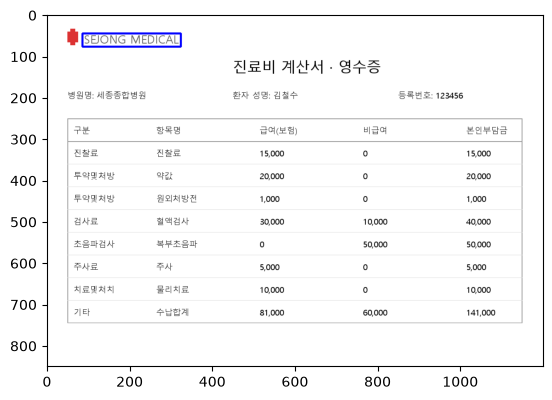

In [5]:
# 3. OpenCV로 사각형을 그리기 위한 좌상단/우하단 좌표 정수 변환
import matplotlib.pyplot as plt
top_left = (int(bbox[0][0]), int(bbox[0][1]))      # [338, 198]
bottom_right = (int(bbox[2][0]), int(bbox[2][1]))  # [894, 311]

# 4. 이미지 위에 빨간색(BGR: 0,0,255) 사각형 그리고 저장
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.rectangle(img_rgb, top_left, bottom_right, (0, 0, 255), 3) # 두께 3

plt.imshow(img_rgb)

In [6]:
ocr_results[0]

([[np.int32(86), np.int32(44)],
  [np.int32(324), np.int32(44)],
  [np.int32(324), np.int32(76)],
  [np.int32(86), np.int32(76)]],
 'SEJONG MEDICAL',
 np.float64(0.8624694909214918))

In [7]:
# ==========================================================
# Step 4. 추출된 데이터 뜯어보기 (데이터 구조 학습)
# ==========================================================
print("\n=== [OCR 분석 결과 출력] ===")

# ocr_results는 [ (좌표), "텍스트", 신뢰도 ] 형태의 리스트(List) 덩어리입니다.
# 반복문(for)을 돌면서 하나씩 꺼내어 확인해 봅니다.
for index, element in enumerate(ocr_results, start=1):
    # 각 요소에서 좌표(bbox), 글자(text), 확신 수준(prob)을 분리합니다.
    bbox = element[0]  # 글자를 감싸는 사각형의 네 꼭짓점 좌표 [[x1,y1], [x2,y2], [x3,y3], [x4,y4]]
    text = element[1]  # AI가 인식한 텍스트 문자열
    prob = element[2]  # AI가 해당 글자라고 확신하는 확률 (0.0 ~ 1.0 사이)

    # 가독성을 위해 신뢰도를 백분율(%)로 변환합니다.
    confidence_pct = prob * 100

    # 콘솔 창에 친절하게 출력
    print(f"[{index:02d}] 추출 문자: '{text}' (신뢰도: {confidence_pct:.1f}%)")
    print(f"     └─ 위치 좌표: {bbox}")
    print("-" * 50)

print("\n모든 이미지 분석이 완료되었습니다!")


=== [OCR 분석 결과 출력] ===
[01] 추출 문자: 'SEJONG MEDICAL' (신뢰도: 86.2%)
     └─ 위치 좌표: [[np.int32(86), np.int32(44)], [np.int32(324), np.int32(44)], [np.int32(324), np.int32(76)], [np.int32(86), np.int32(76)]]
--------------------------------------------------
[02] 추출 문자: '진료비 계산서' (신뢰도: 91.1%)
     └─ 위치 좌표: [[np.int32(448), np.int32(102)], [np.int32(682), np.int32(102)], [np.int32(682), np.int32(150)], [np.int32(448), np.int32(150)]]
--------------------------------------------------
[03] 추출 문자: '영수증' (신뢰도: 99.7%)
     └─ 위치 좌표: [[np.int32(700), np.int32(102)], [np.int32(812), np.int32(102)], [np.int32(812), np.int32(150)], [np.int32(700), np.int32(150)]]
--------------------------------------------------
[04] 추출 문자: '병원명: 세종종합병원' (신뢰도: 60.5%)
     └─ 위치 좌표: [[np.int32(50), np.int32(179)], [np.int32(244), np.int32(179)], [np.int32(244), np.int32(210)], [np.int32(50), np.int32(210)]]
--------------------------------------------------
[05] 추출 문자: '환자 성명: 김철수' (신뢰도: 54.6%)
     └─ 위치 좌표: [[np

In [8]:
#############################3
# 글자만 추출하여서 RAG할 txt원본 만들기
###############################

extracted_lines=[]
for element in ocr_results:
    text = element[1]  # [좌표, 텍스트, 신뢰도] 구조에서 '텍스트'만 추출
    extracted_lines.append(text)

# 추출된 모든 단어/문장들을 줄바꿈(\n)으로 이어 붙여 하나의 문서 텍스트로 만듭니다.
full_ocr_text = "\n".join(extracted_lines)
full_ocr_text

'SEJONG MEDICAL\n진료비 계산서\n영수증\n병원명: 세종종합병원\n환자 성명: 김철수\n등록번호: 123456\n구분\n항독명\n급여(보험)\n비급여\n본인부담금\n진찰료\n진찰료\n15,000\n15,000\n투약및처방\n약값\n20,000\n20,000\n투약및처방\n원외처방전\n1,000\n1,000\n검사료\n혈액검사\n30,000\n10,000\n40,000\n초음파검사\n복부초음파\n50,000\n50,000\n주사료\n주사\n5,000\n5,000\n치료및처지\n물리치료\n10,000\n10,000\n기타\n수남합계\n81,000\n60,000\n141,000'

In [9]:
# ==========================================================
# 3. RAG를 위한 텍스트 스플리터 (행 단위 가위질)
# ==========================================================
print("=== [추출 데이터 기반 RAG Chunking 시작] ===")

# 의미 있는 최소 단위(Chunk)로 쪼개어 LLM이 문맥을 놓치지 않도록 준비합니다.
chunks = full_ocr_text.strip().split("\n")

# 4. 결과 확인 (Vector DB에 들어갈 최종 조각들)
for index, chunk in enumerate(chunks, start=1):
    print(f"🧩 청크 [{index:02d}]: {chunk}")

print("===========================================")
print(f"실제 이미지에서 추출한 데이터로 {len(chunks)}개의 Chunk 생성 완료!")

=== [추출 데이터 기반 RAG Chunking 시작] ===
🧩 청크 [01]: SEJONG MEDICAL
🧩 청크 [02]: 진료비 계산서
🧩 청크 [03]: 영수증
🧩 청크 [04]: 병원명: 세종종합병원
🧩 청크 [05]: 환자 성명: 김철수
🧩 청크 [06]: 등록번호: 123456
🧩 청크 [07]: 구분
🧩 청크 [08]: 항독명
🧩 청크 [09]: 급여(보험)
🧩 청크 [10]: 비급여
🧩 청크 [11]: 본인부담금
🧩 청크 [12]: 진찰료
🧩 청크 [13]: 진찰료
🧩 청크 [14]: 15,000
🧩 청크 [15]: 15,000
🧩 청크 [16]: 투약및처방
🧩 청크 [17]: 약값
🧩 청크 [18]: 20,000
🧩 청크 [19]: 20,000
🧩 청크 [20]: 투약및처방
🧩 청크 [21]: 원외처방전
🧩 청크 [22]: 1,000
🧩 청크 [23]: 1,000
🧩 청크 [24]: 검사료
🧩 청크 [25]: 혈액검사
🧩 청크 [26]: 30,000
🧩 청크 [27]: 10,000
🧩 청크 [28]: 40,000
🧩 청크 [29]: 초음파검사
🧩 청크 [30]: 복부초음파
🧩 청크 [31]: 50,000
🧩 청크 [32]: 50,000
🧩 청크 [33]: 주사료
🧩 청크 [34]: 주사
🧩 청크 [35]: 5,000
🧩 청크 [36]: 5,000
🧩 청크 [37]: 치료및처지
🧩 청크 [38]: 물리치료
🧩 청크 [39]: 10,000
🧩 청크 [40]: 10,000
🧩 청크 [41]: 기타
🧩 청크 [42]: 수남합계
🧩 청크 [43]: 81,000
🧩 청크 [44]: 60,000
🧩 청크 [45]: 141,000
실제 이미지에서 추출한 데이터로 45개의 Chunk 생성 완료!


- EasyOCR의 기본 readtext()는 이미지 안에서 글자 박스를 찾을 때, 하나의 긴 행이 아니라 띄어쓰기나 칸막이가 있는 단어 단위로 박스를 따로따로 쪼개서 검출함
- 그 상태에서 단순하게 리스트를 바로 조각내면 표의 행 구조가 완전히 무너집니다.

🛠️ 해결책 1. EasyOCR의 paragraph=True 옵션 사용 (가장 간단함)
-  paragraph=True 옵션을 주면, AI가 같은 라인(Y축 높이가 비슷한)에 가깝게 붙어 있는 단어들을 하나의 줄(Line) 단위로 알아서 묶어서 뱉어줍니다.

In [10]:
import easyocr

reader = easyocr.Reader(['ko', 'en'], gpu=False)
results = reader.readtext("ocr1.png", detail=1)

lines = {}
threshold = 30  # 💡 임계값을 30픽셀로 늘려 미세한 높낮이 차이를 무시합니다.

for element in results:
    bbox = element[0]
    text = element[1]

    # 좌상단(bbox[0][1])과 좌하단(bbox[3][1])의 중간값(중심점)을 Y축 기준으로 사용
    y_center = (bbox[0][1] + bbox[3][1]) / 2

    matched_y = None
    for registered_y in lines.keys():
        # 중심점 간의 거리가 threshold 이내면 무조건 같은 줄로 판정
        if abs(registered_y - y_center) < threshold:
            matched_y = registered_y
            break

    if matched_y is not None:
        lines[matched_y].append((bbox[0][0], text))
    else:
        lines[y_center] = [(bbox[0][0], text)]

# 위 ➡️ 아래 정렬
sorted_y_keys = sorted(lines.keys())
chunks = []

for y in sorted_y_keys:
    # 왼쪽 ➡️ 오른쪽 정렬
    line_elements = sorted(lines[y], key=lambda x: x[0])
    combined_line = " ".join([item[1] for item in line_elements])
    chunks.append(combined_line)

print("=== [최종 보정 후 RAG Chunking 결과] ===")
for index, chunk in enumerate(chunks, start=1):
    print(f"🧩 청크 [{index:02d}]: {chunk}")

Using CPU. Note: This module is much faster with a GPU.
c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


=== [최종 보정 후 RAG Chunking 결과] ===
🧩 청크 [01]: SEJONG MEDICAL
🧩 청크 [02]: 진료비 계산서 영수증
🧩 청크 [03]: 병원명: 세종종합병원 환자 성명: 김철수 등록번호: 123456
🧩 청크 [04]: 구분 항독명 급여(보험) 비급여 본인부담금
🧩 청크 [05]: 진찰료 진찰료 15,000 15,000
🧩 청크 [06]: 투약및처방 약값 20,000 20,000
🧩 청크 [07]: 투약및처방 원외처방전 1,000 1,000
🧩 청크 [08]: 검사료 혈액검사 30,000 10,000 40,000
🧩 청크 [09]: 초음파검사 복부초음파 50,000 50,000
🧩 청크 [10]: 주사료 주사 5,000 5,000
🧩 청크 [11]: 치료및처지 물리치료 10,000 10,000
🧩 청크 [12]: 기타 수남합계 81,000 60,000 141,000


# 표의 형태로변경

In [11]:
# 3. 마크다운 표 변수화하기 (출력 대신 변수에 저장)
chunks = []

# 표의 헤더 양식 먼저 리스트에 담기
chunks.append("| 구분 | 항목명 | 급여(보험) | 비급여 | 본인부담금 |")
chunks.append("| --- | --- | --- | --- | --- |")

# 위에서 아래 순서로 한 줄씩 순차 탐색
for y in sorted(lines.keys()):
    sorted_words = sorted(lines[y], key=lambda x: x[0])
    row_text_list = [item[1] for item in sorted_words]

    line_str = "".join(row_text_list)
    if any(k in line_str for k in ["진료비", "병원명", "SEJONG", "MEDICAL", "구분", "항목명"]):
        continue

    # 💡 화면에 print하는 대신 chunks 리스트에 문자열로 추가(append)합니다.
    md_line = f"| {' | '.join(row_text_list)} |"
    chunks.append(md_line)


# ==========================================================
#  바로 이 변수(dynamic_context)가 LLM으로 보낼 최종 변수입니다!
# ==========================================================
dynamic_context = "\n".join(chunks)

# 확인용 출력
print(dynamic_context)

| 구분 | 항목명 | 급여(보험) | 비급여 | 본인부담금 |
| --- | --- | --- | --- | --- |
| 진찰료 | 진찰료 | 15,000 | 15,000 |
| 투약및처방 | 약값 | 20,000 | 20,000 |
| 투약및처방 | 원외처방전 | 1,000 | 1,000 |
| 검사료 | 혈액검사 | 30,000 | 10,000 | 40,000 |
| 초음파검사 | 복부초음파 | 50,000 | 50,000 |
| 주사료 | 주사 | 5,000 | 5,000 |
| 치료및처지 | 물리치료 | 10,000 | 10,000 |
| 기타 | 수남합계 | 81,000 | 60,000 | 141,000 |


# 3단계- RAG

In [12]:
import os
from dotenv import load_dotenv
# 랭체인 필수 컴포넌트
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# 0. .env 파일의 환경변수 로드
load_dotenv()

# [메모리 데이터 연동]
# chunks: 앞서 빌드한 마크다운 행 리스트
# chunk_embeddings: OpenAI text-embedding-3-small 벡터 배열

# 1. 랭체인 인터페이스로 기존 FAISS 인덱스 래핑
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
text_embedding_pairs = zip(chunks, chunk_embeddings.tolist())

vectorstore = FAISS.from_embeddings(
    text_embeddings=text_embedding_pairs,
    embedding=embeddings
)

# 상위 2개 행을 뽑아오는 리트리버 정의
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

# 2. 연산/합계를 금지하는 콤팩트한 프롬프트 템플릿
prompt = ChatPromptTemplate.from_messages([
    ("system", "너는 명세서 데이터를 그대로 읽어주는 어시스턴트야.\n"
               "절대 숫자를 더하거나 합계를 내는 등의 연산을 하지 마.\n"
               "오직 제공된 데이터에 적힌 글자와 숫자 그대로만 답변해줘."),
    ("user", "아래 명세서 데이터를 바탕으로 질문에 답해줘.\n\n"
             "[명세서 데이터]\n{context}\n\n"
             "[질문]\n{question}")
])

llm = ChatOpenAI(model="gpt-4o", temperature=0.0)
output_parser = StrOutputParser()

# 3. LCEL 체인 조립 (R -> G 파이프라인)
rag_chain = (
    {"context": retriever, "question": RunnablePassthrough()}
    | prompt
    | llm
    | output_parser
)

# 4. 단순 사실 확인용 질문으로 변경
user_question = "검사료 항목의 급여 금액과 비급여 금액은 각각 얼마야?"

print("🤖 랭체인 리트리버 구동 및 단순 정보 매핑 중...")
response_content = rag_chain.invoke(user_question)

print("\n=== [랭체인 RAG 최종 답변] ===")
print(response_content)
print("===================================")

C:\Users\Admin\AppData\Local\Temp\ipykernel_10572\1290620503.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


NameError: name 'chunk_embeddings' is not defined